In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import jax
from jax.typing import ArrayLike
from jax import numpy as jnp # JAX version of NumPy.
from flax import nnx # Neural networks in JAX.
import optax # Optimization in JAX.
import gymnasium as gym
import numpy as np # For compatibility with gymnasium.
from tqdm import tqdm
import pennylane as qml
import json
import yaml
import tyro
from pathlib import Path
import qnrl

jax.config.update("jax_enable_x64", True) # Enable double-precision (default is single-precision).

## Load Config

In [3]:
# Load config from file.
cfg_path = Path("./experiments/qnrl_CartPole-v1_quantum-QuantumNativeQNetworkSplit-partition-rev.py")
# cfg_path = Path("./experiments/qnrl_CartPole-v1_quantum-QuantumNativeQNetworkSplit-lr=1e-2.py")
# cfg_path = Path("./experiments/qnrl_CartPole-v1_quantum-QuantumNativeQNetworkSplit-lr=1e-3.py")
# cfg_path = Path("./experiments/qnrl_CartPole-v1_quantum-QuantumNativeQNetworkSplit-lr=25e-5.py")
module = qnrl.tools.load_python_module_from_filepath(cfg_path)
config = module.config

nnx.display(config)

## Debug

In [4]:
# model_policy = config.model_policy
# model_target = config.model_target

# env = config.env.make()


# # Seed random generators.
# seed = config.seed
# np.random.seed(seed)
# env.action_space.seed(seed)
# key = jax.random.PRNGKey(seed)
# key, subkey = jax.random.split(key)

# # Reset the environment.
# observation, _ = env.reset(seed=seed)


# for _ in range(10):

#     target_action_pmfs = model_target.call_gen_action_dist(observation)
#     action_pmfs = model_policy.call_gen_action_dist(observation)
    
#     key, subkey = jax.random.split(key)
#     action = jax.random.choice(key=subkey, a=config.model_policy.n_actions, p=action_pmfs.squeeze()).item()
    
#     print(f"{target_action_pmfs = }")
#     print(f"{action_pmfs = }")
#     print(f"{action = }")
    
#     next_observation, reward, done, truncation, info = env.step(action)
#     observation = next_observation.copy()
    
#     if done:
#         break

## Train

In [5]:
history_list, buffer = config.train(
    # batch_size=64,
    # learning_starts=100,
    # target_update_frequency=20,
    # metric_manager=None,
    # checkpoint_manager=None,
    return_buffer=True,
)

  0%|          | 0/500000 [00:00<?, ?step/s]/Users/derieux/.pyenv/versions/qnrl/lib/python3.12/site-packages/jax/_src/ops/scatter.py:108: FutureWarning: scatter inputs have incompatible types: cannot safely cast value from dtype=float64 to dtype=float32 with jax_numpy_dtype_promotion='standard'. In future JAX releases this will result in an error.
  warnings.warn(
  2%|▏         | 10940/500000 [11:01<8:12:48, 16.54step/s, episode_step=10923, episode_reward=21, episode_length=21, episode_time=13.9, loss_step=10930, loss=4.42061114437677]   


In [9]:
key = jax.random.PRNGKey(2)

In [29]:
# Inspect the buffer.
key, subkey = jax.random.split(key=key)
slc = buffer.sample(key=key, batch_size=30)
# slc = buffer[:30]
nnx.display(list(dict(pmf=pmf.tolist(), action=action.tolist()) for pmf,action in zip(slc.action_pmfs.squeeze(), slc.actions.squeeze())))

In [30]:
history_dict = qnrl.tools.listofdict_to_dictoflist(history_list)

Text(0, 0.5, 'episode_reward')

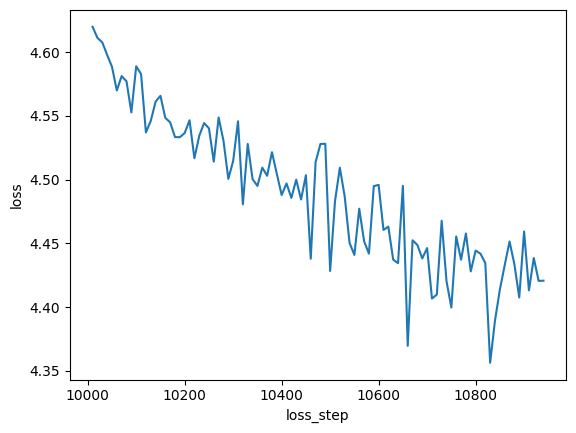

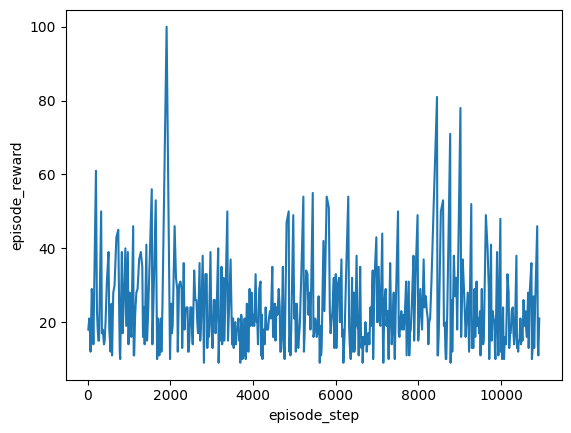

In [31]:
import matplotlib.pyplot as plt

plt.figure()
plt.plot(history_dict['loss_step'], history_dict['loss'])
plt.xlabel('loss_step')
plt.ylabel('loss')

plt.figure()
plt.plot(history_dict['episode_step'], history_dict['episode_reward'])
plt.xlabel('episode_step')
plt.ylabel('episode_reward')

## Evaluate

In [11]:
config.eval(total_timesteps=500)

  3%|▎         | 13/500 [00:00<00:17, 27.85step/s, episode_step=13, episode_reward=14, episode_length=14, episode_time=0.467]


[{'pmfs': Array([[0.45, 0.55]], dtype=float64),
  'action': 1,
  'reward': 1.0,
  'observation': Array([ 0.005598  , -0.01207025,  0.22877487, -0.01163877], dtype=float64),
  'next_observation': Array([ 0.00534654,  0.06569025,  0.22600373, -0.12249728], dtype=float64),
  'done': False},
 {'pmfs': Array([[0.44, 0.56]], dtype=float64),
  'action': 1,
  'reward': 1.0,
  'observation': Array([ 0.00534654,  0.06569025,  0.22600373, -0.12249728], dtype=float64),
  'next_observation': Array([ 0.00671509,  0.1434561 ,  0.1968377 , -0.23343542], dtype=float64),
  'done': False},
 {'pmfs': Array([[0.52, 0.48]], dtype=float64),
  'action': 0,
  'reward': 1.0,
  'observation': Array([ 0.00671509,  0.1434561 ,  0.1968377 , -0.23343542], dtype=float64),
  'next_observation': Array([ 0.00970376,  0.06518574,  0.14125785, -0.11127044], dtype=float64),
  'done': False},
 {'pmfs': Array([[0.25, 0.75]], dtype=float64),
  'action': 1,
  'reward': 1.0,
  'observation': Array([ 0.00970376,  0.06518574,  0.